# Mental disorders, daily-life interference, and reported care

Judy Chen

## Setup

In [1]:
from pathlib import Path
import csv
import io
import os
import zipfile

import numpy as np
import pandas as pd
from scipy.stats import t

candidates = [
    Path.cwd(),
    Path.cwd() / "milestone2_draft",
    Path.cwd() / "static-viz-project" / "milestone2_draft",
]
DRAFT_DIR = next(
    (path for path in candidates if (path / "static-draft.ipynb").is_file()),
    None,
)
if DRAFT_DIR is None:
    raise FileNotFoundError("Open this notebook from the course repository or its draft folder.")

DATA_DIR = Path(os.environ.get("MENTAL_HEALTH_DATA_DIR", DRAFT_DIR / "data")).expanduser()
CPES_PATH = Path(os.environ.get("CPES_DATA_PATH", DATA_DIR / "20240-0001-Data.dta")).expanduser()
NSDUH_PATH = Path(os.environ.get("NSDUH_DATA_PATH", DATA_DIR / "nsduh2024.zip")).expanduser()
FIGURE_DIR = DRAFT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

missing_files = [path.name for path in (CPES_PATH, NSDUH_PATH) if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Missing local survey files: " + ", ".join(missing_files)
        + ". Follow the data setup in README.md. Raw data are intentionally absent from GitHub."
    )


import altair as alt

alt.renderers.enable("png")

BLUE, ORANGE = "#536D9A", "#B67439"
DISORDER_LABELS = ["Depression", "Generalized anxiety", "Panic disorder", "Social phobia",
                   "Agoraphobia*", "PTSD"]
DISORDER_COLORS = [BLUE, "#9673A6", ORANGE, "#4C9189", "#B85F62", "#827465"]
CARE_COLORS = {"Both": BLUE, "Professional contact only": "#A1B7CF",
               "Medication only": "#9673A6", "Neither reported": ORANGE}
CPES_SOURCE = "CPES 2001–2003 | NCS-R Part 2 + NLAAS"
NSDUH_SOURCE = "NSDUH 2024 | Adults with past-year depression"


def save_chart(chart, filename, title, notes):
    chart = (
        chart.properties(title=alt.TitleParams(text=title, subtitle=notes, anchor="start"))
        .configure(background="white", font="Arial", padding=12)
        .configure_axis(
            labelFontSize=11, titleFontSize=12, titlePadding=9,
            gridColor="#E5E5E5", domainColor="#999999", tickColor="#999999",
            labelLimit=230,
        )
        .configure_legend(labelFontSize=11, titleFontSize=11, padding=8)
        .configure_title(fontSize=14, subtitleFontSize=10, subtitleColor="#555555", offset=12)
        .configure_header(labelFontSize=11, labelFontWeight="normal", title=None)
        .configure_view(stroke=None)
    )
    chart.to_dict(validate=True)
    chart.save(FIGURE_DIR / filename, scale_factor=2)
    return chart


In [2]:
DISORDERS = {
    "Major depressive disorder": {
        "diagnosis": "V07655", "social": "V00992",
        "domains": ["V00989", "V00991", "V00992"],
        "professional_care": "V01013", "ever_help": "V00995",
    },
    "Generalized anxiety disorder": {
        "diagnosis": "V07613", "social": "V01870",
        "domains": ["V01867", "V01869", "V01870"],
        "professional_care": "V01891", "ever_help": "V01874",
    },
    "Panic disorder": {
        "diagnosis": "V07716", "social": "V01353",
        "domains": ["V01350", "V01352", "V01353"],
        "professional_care": "V01394", "ever_help": "V01357",
    },
    "Social phobia": {
        "diagnosis": "V07748", "social": "V01579",
        "domains": ["V01576", "V01578", "V01579"],
        "professional_care": "V01621", "ever_help": "V01583",
    },
    "Agoraphobia without panic disorder": {
        "diagnosis": "V07513", "social": "V01692",
        "domains": ["V01689", "V01691", "V01692"],
        "professional_care": "V01734", "ever_help": "V01697",
    },
    "PTSD": {
        "diagnosis": "V07725", "social": "V04037",
        "domains": ["V04034", "V04036", "V04037"],
        "professional_care": "V04040", "ever_help": None,
    },
}
MEDICATIONS = {
    "Antidepressants": "V02614", "Tranquilizers": "V02616",
    "Stimulants": "V02617", "Antipsychotics": "V02620",
    "Sleeping pills/sedatives": "V02807",
}
cpes_columns = {"CPESCASE", "CPESPROJ", "NCNLWTLG", "SESTRAT", "SECLUSTR"}
for spec in DISORDERS.values():
    cpes_columns.update([
        spec["diagnosis"], spec["social"], spec["professional_care"], spec["ever_help"],
        *spec["domains"],
    ])
cpes_columns.discard(None)
cpes_columns.update(MEDICATIONS.values())

with pd.io.stata.StataReader(CPES_PATH, convert_categoricals=False) as reader:
    cpes_labels = reader.variable_labels()
    cpes_source_rows = int(reader._nobs)
    cpes_source_columns = len(cpes_labels)
cpes_raw = pd.read_stata(CPES_PATH, columns=sorted(cpes_columns), convert_categoricals=False)
cpes = cpes_raw.loc[cpes_raw["NCNLWTLG"].gt(0)].copy()
assert cpes_source_rows == 20_013 and cpes_source_columns == 5_543
assert cpes_raw["CPESCASE"].nunique() == 20_013 and len(cpes) == 10_341

nsduh_columns = [
    "IRAMDEYR", "IRAMDEIMP", "ATXMDEYR", "ARXMDEYR", "AMDETXRX",
    "ANALWT2_C", "VESTR_C", "VEREP", "IRINSUR4", "AGE3", "INCOME", "POVERTY3",
]
with zipfile.ZipFile(NSDUH_PATH) as archive:
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_source_columns = len(next(csv.reader(io.TextIOWrapper(stream), delimiter="\t")))
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_raw = pd.read_csv(stream, sep="\t", usecols=nsduh_columns, na_values=["."])
assert len(nsduh_raw) == 58_633 and nsduh_source_columns == 2_632
nsduh_adults = nsduh_raw.loc[nsduh_raw["IRAMDEYR"].isin([0, 1])].copy()
nsduh_mde = nsduh_adults.loc[nsduh_adults["IRAMDEYR"].eq(1)].copy()
care_known = nsduh_mde["ATXMDEYR"].isin([0, 1]) & nsduh_mde["ARXMDEYR"].isin([0, 1])
nsduh_care = nsduh_mde.loc[care_known].copy()
nsduh_care["care_group"] = np.select([
    nsduh_care["ATXMDEYR"].eq(1) & nsduh_care["ARXMDEYR"].eq(1),
    nsduh_care["ATXMDEYR"].eq(1),
    nsduh_care["ARXMDEYR"].eq(1),
], ["Both", "Professional contact only", "Medication only"], default="Neither reported")
nsduh_care["reported_either"] = nsduh_care["ATXMDEYR"].eq(1) | nsduh_care["ARXMDEYR"].eq(1)
assert len(nsduh_adults) == 47_299 and len(nsduh_mde) == 5_205
assert len(nsduh_care) == 5_008 and (~care_known).sum() == 197


care_values = {}
care_coverage = []
for name, spec in DISORDERS.items():
    observed = cpes[spec["professional_care"]]
    care = observed.map({1: 1.0, 5: 0.0})
    inferred_no = pd.Series(False, index=cpes.index)
    if spec["ever_help"] is not None:
        never_help = cpes[spec["ever_help"]].eq(5)
        assert not (never_help & observed.eq(1)).any()
        # An explicit lifetime "no" rules out past-year help for this disorder.
        inferred_no = observed.isna() & never_help
        care = care.mask(inferred_no, 0.0)
    # PTSD's lifetime item concerns a selected event: do not infer from it.
    care_values[name] = care
    cases = cpes[spec["diagnosis"]].eq(1)
    care_coverage.append({"name": name, "cases": int(cases.sum()),
                          "known": int((cases & care.notna()).sum()),
                          "inferred_no": int((cases & inferred_no).sum())})
assert [r["known"] for r in care_coverage] == [916, 496, 353, 849, 220, 257]


In [3]:
def survey_mean(frame, values, domain=None, *, weight, strata, cluster):
    """Estimate a domain mean/ratio and its design-based standard error."""
    y = pd.Series(values, index=frame.index, dtype=float)
    active = y.notna()
    if domain is not None:
        active &= pd.Series(domain, index=frame.index).fillna(False).astype(bool)
    w = frame[weight].astype(float)
    if not np.isfinite(w).all() or not w.gt(0).all():
        raise ValueError("Use a full analysis pool with finite, positive survey weights.")
    if frame[[strata, cluster]].isna().any().any():
        raise ValueError("Missing survey design identifiers need investigation.")
    denominator = w.loc[active].sum()
    if denominator <= 0:
        raise ValueError("No valid weighted observations in the requested domain.")
    estimate = float(np.average(y.loc[active], weights=w.loc[active]))
    residual = (y - estimate).where(active, 0.0)
    design = frame[[strata, cluster]].copy()
    design["linearized"] = w * residual / denominator
    psu_totals = design.groupby([strata, cluster], observed=True)["linearized"].sum()
    components = psu_totals.groupby(level=0).agg(["count", "sum"])
    if components["count"].lt(2).any():
        raise ValueError("A single-PSU stratum needs a documented variance treatment.")
    centered = psu_totals - psu_totals.groupby(level=0).transform("mean")
    square_sums = centered.pow(2).groupby(level=0).sum()
    m = components["count"]
    variance = float((m / (m - 1) * square_sums).sum())
    se = float(np.sqrt(max(variance, 0)))
    degrees_freedom = int((m - 1).sum())
    critical = float(t.ppf(0.975, degrees_freedom))
    return {
        "estimate": estimate, "se": se,
        "lower": estimate - critical * se, "upper": estimate + critical * se,
        "n": int(active.sum()), "design_df": degrees_freedom,
    }

CPES_DESIGN = {"weight": "NCNLWTLG", "strata": "SESTRAT", "cluster": "SECLUSTR"}
NSDUH_DESIGN = {"weight": "ANALWT2_C", "strata": "VESTR_C", "cluster": "VEREP"}


## Figure 01 · Past-year prevalence

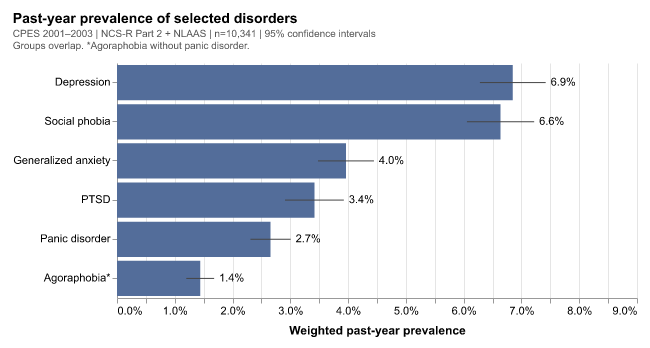

In [4]:
prevalence = pd.DataFrame([
    {"name": label, **survey_mean(cpes, cpes[spec["diagnosis"]].map({1: 1., 5: 0.}), **CPES_DESIGN)}
    for label, spec in zip(DISORDER_LABELS, DISORDERS.values())
]).sort_values("estimate")


def prevalence_chart(df):
    base = alt.Chart(df).encode(
        y=alt.Y("name:N", sort="-x", title=None),
    )
    bars = base.mark_bar(color=BLUE).encode(
        x=alt.X("estimate:Q", title="Weighted past-year prevalence", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .085])),
    )
    intervals = base.mark_rule(color="#444444").encode(x="lower:Q", x2="upper:Q")
    labels = base.mark_text(align="left", dx=5).encode(
        x="upper:Q", text=alt.Text("estimate:Q", format=".1%"),
    )
    return (bars + intervals + labels).properties(width=520, height=235)


save_chart(
    prevalence_chart(prevalence), "01_prevalence.png", "Past-year prevalence of selected disorders",
    [CPES_SOURCE + " | n=10,341 | 95% confidence intervals",
     "Groups overlap. *Agoraphobia without panic disorder."],
)


## Figure 02 · Pairwise co-occurrence

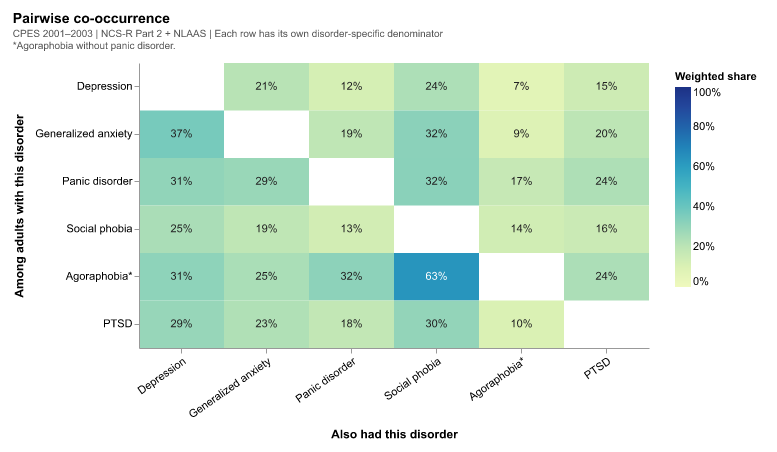

In [5]:
diagnosis_columns = [spec["diagnosis"] for spec in DISORDERS.values()]
assert cpes[diagnosis_columns].isin([1, 5]).all().all()
flags = cpes[diagnosis_columns].eq(1).to_numpy()
weights = cpes["NCNLWTLG"].to_numpy()
cooccurrence = np.full((6, 6), np.nan)
for row in range(6):
    for col in range(6):
        if row != col:
            cooccurrence[row, col] = np.average(flags[flags[:, row], col], weights=weights[flags[:, row]])*100


cooccurrence_df = pd.DataFrame([
    {"disorder": DISORDER_LABELS[row], "also_had": DISORDER_LABELS[col],
     "share": cooccurrence[row, col] / 100}
    for row in range(6) for col in range(6) if row != col
])


def cooccurrence_chart(df):
    base = alt.Chart(df).encode(
        x=alt.X("also_had:N", title="Also had this disorder", sort=DISORDER_LABELS,
                axis=alt.Axis(labelAngle=-35)),
        y=alt.Y("disorder:N", title="Among adults with this disorder", sort=DISORDER_LABELS),
    )
    cells = base.mark_rect().encode(
        color=alt.Color("share:Q", title="Weighted share", scale=alt.Scale(scheme="yellowgreenblue", domain=[0, 1]),
                        legend=alt.Legend(format="%")),
    )
    labels = base.mark_text().encode(
        text=alt.Text("share:Q", format=".0%"),
        color=alt.condition("datum.share > .6", alt.value("white"), alt.value("#222222")),
    )
    return (cells + labels).properties(width=510, height=285)


save_chart(
    cooccurrence_chart(cooccurrence_df), "02_cooccurrence_heatmap.png", "Pairwise co-occurrence",
    [CPES_SOURCE + " | Each row has its own disorder-specific denominator",
     "*Agoraphobia without panic disorder."],
)


## Figure 03 · Comorbid disorder combinations

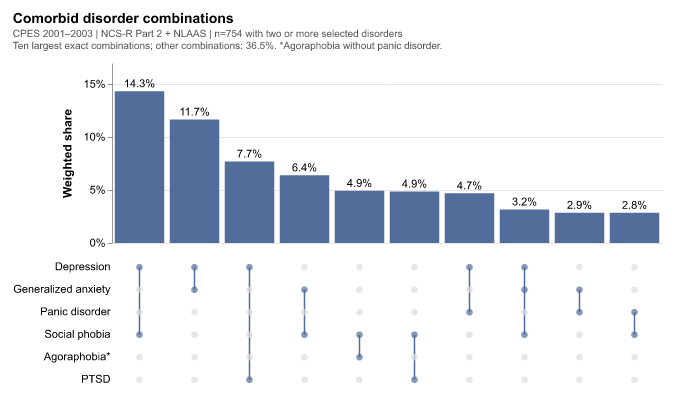

In [6]:
bits = flags.astype(int)
patterns = (bits * (2**np.arange(6))).sum(axis=1)
disorder_count = bits.sum(axis=1)
multi = disorder_count >= 2
pattern_weights = pd.DataFrame({"pattern": patterns[multi], "weight": weights[multi]}).groupby("pattern")["weight"].sum()
shares = pattern_weights.sort_values(ascending=False).head(10) / pattern_weights.sum()*100
assert all(int(p).bit_count() >= 2 for p in shares.index)
omitted_share = 100-shares.sum()


combinations = [str(pattern) for pattern in shares.index]
combination_df = pd.DataFrame({"combination": combinations, "share": shares.to_numpy() / 100})
membership_df = pd.DataFrame([
    {"combination": str(pattern), "disorder": label, "included": bool(int(pattern) & (2**row))}
    for pattern in shares.index for row, label in enumerate(DISORDER_LABELS)
])
links_df = pd.DataFrame([
    {"combination": str(pattern),
     "first": DISORDER_LABELS[min(row for row in range(6) if int(pattern) & (2**row))],
     "last": DISORDER_LABELS[max(row for row in range(6) if int(pattern) & (2**row))]}
    for pattern in shares.index
])


def combinations_chart(bars_df, dots_df, lines_df):
    bars = alt.Chart(bars_df).mark_bar(color=BLUE).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=alt.Y("share:Q", title="Weighted share", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .17])),
    )
    labels = bars.mark_text(dy=-7).encode(text=alt.Text("share:Q", format=".1%"))
    dots = alt.Chart(dots_df).mark_point(filled=True, size=45).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=alt.Y("disorder:N", sort=DISORDER_LABELS, scale=alt.Scale(domain=DISORDER_LABELS),
                title=None, axis=alt.Axis(ticks=False, domain=False)),
        color=alt.condition("datum.included", alt.value(BLUE), alt.value("#DDDDDD")),
    )
    lines = alt.Chart(lines_df).mark_rule(color=BLUE, strokeWidth=1.5).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=alt.Y("first:N", sort=DISORDER_LABELS, scale=alt.Scale(domain=DISORDER_LABELS), title=None), y2="last:N",
    )
    return alt.vconcat(
        (bars + labels).properties(width=550, height=180),
        (lines + dots).properties(width=550, height=135), spacing=8,
    ).resolve_scale(x="shared")


save_chart(
    combinations_chart(combination_df, membership_df, links_df), "03_upset.png", "Comorbid disorder combinations",
    [CPES_SOURCE + f" | n={multi.sum():,} with two or more selected disorders",
     f"Ten largest exact combinations; other combinations: {omitted_share:.1f}%. *Agoraphobia without panic disorder."],
)


## Figure 04 · Social-life interference distributions

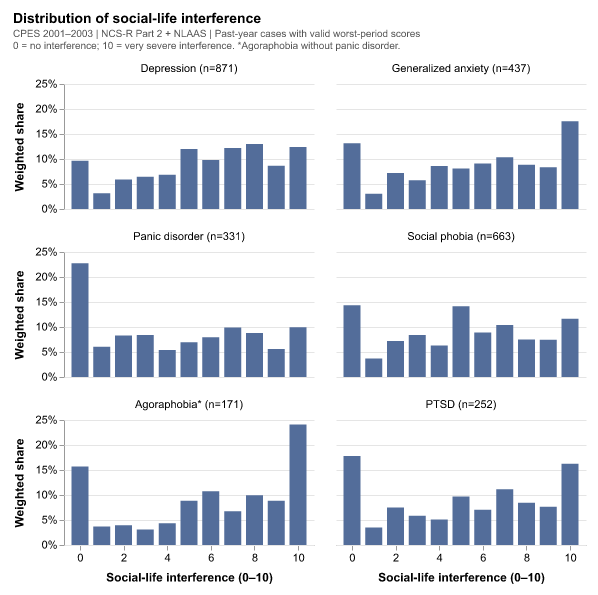

In [7]:
score_distributions, score_counts = [], []
for spec in DISORDERS.values():
    valid = cpes[spec["diagnosis"]].eq(1) & cpes[spec["social"]].between(0, 10)
    counts = cpes.loc[valid].groupby(spec["social"])["NCNLWTLG"].sum().reindex(range(11), fill_value=0)
    score_distributions.append(counts / counts.sum()*100)
    score_counts.append(int(valid.sum()))
max_height = np.ceil(max(row.max() for row in score_distributions)/5)*5


panel_order = [f"{label} (n={n:,})" for label, n in zip(DISORDER_LABELS, score_counts)]
distribution_df = pd.DataFrame([
    {"panel": panel, "score": score, "share": float(distribution.loc[score]) / 100}
    for panel, distribution in zip(panel_order, score_distributions) for score in range(11)
])


def interference_distributions(df):
    bars = alt.Chart(df).mark_bar(color=BLUE, size=17).encode(
        x=alt.X("score:Q", title="Social-life interference (0–10)", scale=alt.Scale(domain=[-.5, 10.5]),
                axis=alt.Axis(values=[0, 2, 4, 6, 8, 10], grid=False)),
        y=alt.Y("share:Q", title="Weighted share", scale=alt.Scale(domain=[0, max_height / 100]),
                axis=alt.Axis(format="%", tickCount=5)),
    ).properties(width=250, height=125)
    return bars.facet(facet=alt.Facet("panel:N", sort=panel_order, title=None), columns=2, spacing=22)


save_chart(
    interference_distributions(distribution_df), "04_social_interference_distributions.png", "Distribution of social-life interference",
    [CPES_SOURCE + " | Past-year cases with valid worst-period scores",
     "0 = no interference; 10 = very severe interference. *Agoraphobia without panic disorder."],
)


## Figure 05 · Daily-life domains

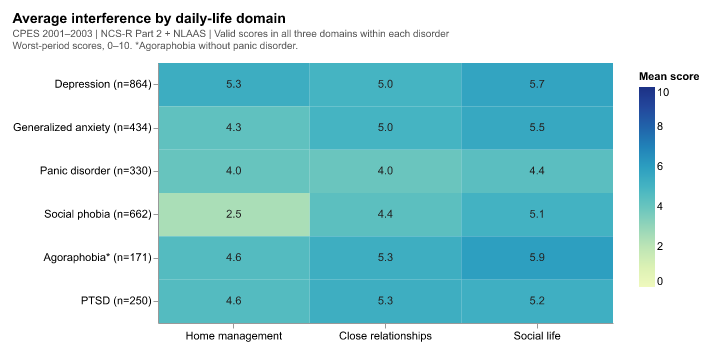

In [8]:
domain_means, complete_counts = [], []
for spec in DISORDERS.values():
    valid = cpes[spec["diagnosis"]].eq(1) & cpes[spec["domains"]].apply(lambda s: s.between(0,10)).all(axis=1)
    domain_means.append([np.average(cpes.loc[valid, v], weights=cpes.loc[valid,"NCNLWTLG"]) for v in spec["domains"]])
    complete_counts.append(int(valid.sum()))
assert complete_counts == [864, 434, 330, 662, 171, 250]


domains = ["Home management", "Close relationships", "Social life"]
domain_labels = [f"{label} (n={n:,})" for label, n in zip(DISORDER_LABELS, complete_counts)]
domain_df = pd.DataFrame([
    {"disorder": domain_labels[row], "domain": domain, "mean_score": domain_means[row][col]}
    for row in range(6) for col, domain in enumerate(domains)
])


def domain_interference_chart(df):
    base = alt.Chart(df).encode(
        x=alt.X("domain:N", sort=domains, title=None, axis=alt.Axis(labelAngle=0)),
        y=alt.Y("disorder:N", sort=domain_labels, title=None),
    )
    cells = base.mark_rect().encode(
        color=alt.Color("mean_score:Q", title="Mean score", scale=alt.Scale(scheme="yellowgreenblue", domain=[0, 10])),
    )
    labels = base.mark_text().encode(
        text=alt.Text("mean_score:Q", format=".1f"),
        color=alt.condition("datum.mean_score > 6", alt.value("white"), alt.value("#222222")),
    )
    return (cells + labels).properties(width=455, height=260)


save_chart(
    domain_interference_chart(domain_df), "05_daily_life_domains.png", "Average interference by daily-life domain",
    [CPES_SOURCE + " | Valid scores in all three domains within each disorder",
     "Worst-period scores, 0–10. *Agoraphobia without panic disorder."],
)


## Figure 06 · Disorder-specific professional care

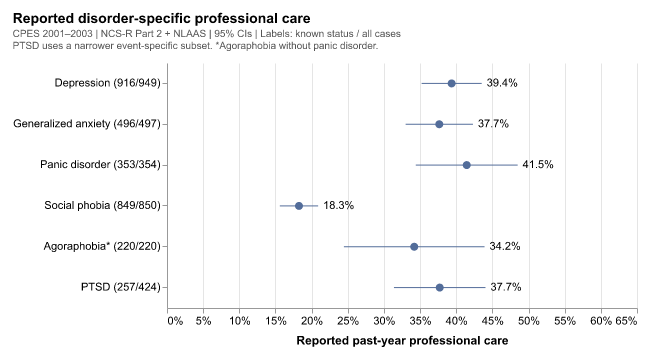

In [9]:
care_rows = []
for label, (name, spec), coverage in zip(DISORDER_LABELS, DISORDERS.items(), care_coverage):
    cases = cpes[spec["diagnosis"]].eq(1)
    result = survey_mean(cpes, care_values[name], cases, **CPES_DESIGN)
    care_rows.append({"label": label, "case_n": coverage["cases"], **result})
professional_care = pd.DataFrame(care_rows)


care_plot = professional_care.assign(
    group=[f"{r.label} ({r.n}/{r.case_n})" for r in professional_care.itertuples()]
)


def professional_care_chart(df):
    base = alt.Chart(df).encode(
        y=alt.Y("group:N", sort=df["group"].tolist(), title=None),
    )
    intervals = base.mark_rule(color=BLUE).encode(
        x=alt.X("lower:Q", title="Reported past-year professional care", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .65])), x2="upper:Q",
    )
    points = base.mark_point(filled=True, opacity=1, color=BLUE, size=65).encode(x="estimate:Q")
    labels = base.mark_text(align="left", dx=5).encode(x="upper:Q", text=alt.Text("estimate:Q", format=".1%"))
    return (intervals + points + labels).properties(width=470, height=245)


save_chart(
    professional_care_chart(care_plot), "06_professional_care.png", "Reported disorder-specific professional care",
    [CPES_SOURCE + " | 95% CIs | Labels: known status / all cases",
     "PTSD uses a narrower event-specific subset. *Agoraphobia without panic disorder."],
)


## Figure 07 · Medication classes

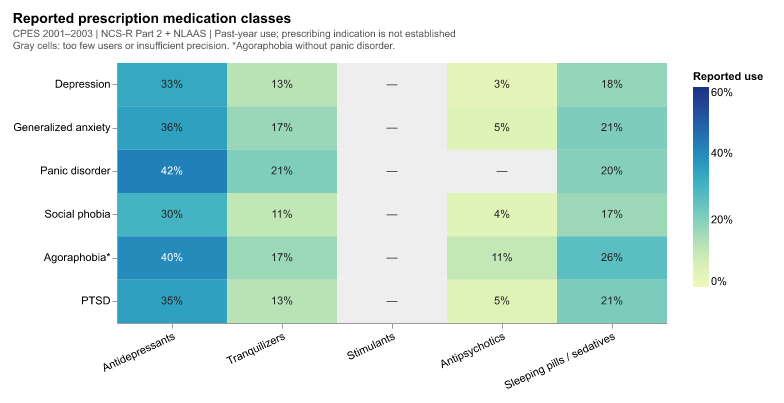

In [10]:
medication_rates = np.full((6, 5), np.nan)
medication_audit = []
for row, (name, spec) in enumerate(DISORDERS.items()):
    cases = cpes[spec["diagnosis"]].eq(1)
    for col, (medication, variable) in enumerate(MEDICATIONS.items()):
        values = cpes[variable].map({1: 1., 5: 0.})
        result = survey_mean(cpes, values, cases, **CPES_DESIGN)
        yes_n = int((cases & values.eq(1)).sum())
        no_n = int((cases & values.eq(0)).sum())
        reliable = result["n"]>=50 and min(yes_n,no_n)>=5 and result["se"]/result["estimate"]<=.30
        medication_audit.append({"disorder": name, "medication": medication, "reliable": reliable, **result})
        if reliable:
            medication_rates[row,col] = result["estimate"]*100


medication_labels = ["Antidepressants", "Tranquilizers", "Stimulants", "Antipsychotics", "Sleeping pills / sedatives"]
medication_df = pd.DataFrame([
    {"disorder": DISORDER_LABELS[row], "medication": medication_labels[col],
     "share": medication_rates[row, col] / 100,
     "label": f"{medication_rates[row, col]:.0f}%" if np.isfinite(medication_rates[row, col]) else "—"}
    for row in range(6) for col in range(5)
])


def medication_chart(df):
    base = alt.Chart(df).encode(
        x=alt.X("medication:N", sort=medication_labels, title=None, axis=alt.Axis(labelAngle=-25)),
        y=alt.Y("disorder:N", sort=DISORDER_LABELS, title=None),
    )
    background = base.mark_rect(color="#EEEEEE")
    cells = base.transform_filter("isValid(datum.share)").mark_rect().encode(
        color=alt.Color("share:Q", title="Reported use", scale=alt.Scale(scheme="yellowgreenblue", domain=[0, .6]),
                        legend=alt.Legend(format="%")),
    )
    labels = base.mark_text().encode(
        text="label:N",
        color=alt.condition("datum.share > .38", alt.value("white"), alt.value("#222222")),
    )
    return (background + cells + labels).properties(width=550, height=260)


save_chart(
    medication_chart(medication_df), "07_medication_classes.png", "Reported prescription medication classes",
    [CPES_SOURCE + " | Past-year use; prescribing indication is not established",
     "Gray cells: too few users or insufficient precision. *Agoraphobia without panic disorder."],
)


## Figure 08 · Interference and antidepressant use

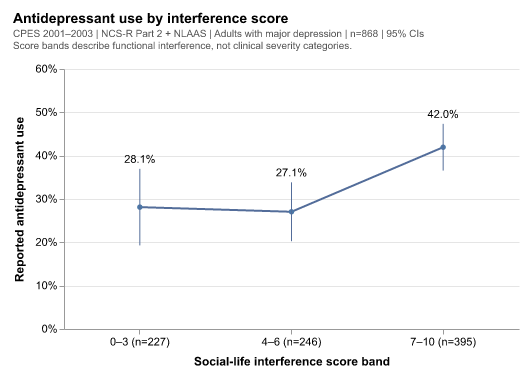

In [11]:
depression = cpes["V07655"].eq(1)
social = cpes["V00992"]
antidepressants = cpes["V02614"].map({1: 1., 5: 0.})
band_results = []
for lower, upper in [(0,3),(4,6),(7,10)]:
    result = survey_mean(cpes, antidepressants, depression & social.between(lower,upper), **CPES_DESIGN)
    band_results.append({"band": f"{lower}–{upper}", **result})
bands = pd.DataFrame(band_results)
assert bands["n"].tolist() == [227,246,395]


band_plot = bands.assign(group=[f"{r.band} (n={r.n})" for r in bands.itertuples()])


def antidepressant_interference_chart(df):
    base = alt.Chart(df).encode(
        x=alt.X("group:O", sort=df["group"].tolist(), title="Social-life interference score band",
                axis=alt.Axis(labelAngle=0)),
    )
    line = base.mark_line(color=BLUE, point=True).encode(
        y=alt.Y("estimate:Q", title="Reported antidepressant use", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .6])),
    )
    intervals = base.mark_rule(color=BLUE).encode(y="lower:Q", y2="upper:Q")
    labels = base.mark_text(dy=-9).encode(y="upper:Q", text=alt.Text("estimate:Q", format=".1%"))
    return (line + intervals + labels).properties(width=455, height=260)


save_chart(
    antidepressant_interference_chart(band_plot), "08_interference_antidepressants.png", "Antidepressant use by interference score",
    [CPES_SOURCE + " | Adults with major depression | n=868 | 95% CIs",
     "Score bands describe functional interference, not clinical severity categories."],
)


## Figure 09 · Interference and professional care

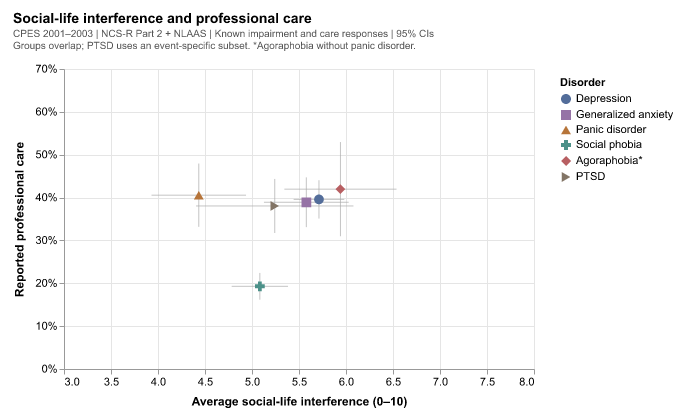

In [12]:
synthesis_rows = []
for label,(name,spec) in zip(DISORDER_LABELS,DISORDERS.items()):
    score=cpes[spec["social"]].where(cpes[spec["social"]].between(0,10))
    domain=cpes[spec["diagnosis"]].eq(1) & score.notna() & care_values[name].notna()
    burden=survey_mean(cpes,score,domain,**CPES_DESIGN)
    care=survey_mean(cpes,care_values[name],domain,**CPES_DESIGN)
    synthesis_rows.append({"label":label,"burden":burden,"care":care})


synthesis_df = pd.DataFrame([
    {"disorder": row["label"], "interference": row["burden"]["estimate"],
     "interference_lower": row["burden"]["lower"], "interference_upper": row["burden"]["upper"],
     "care": row["care"]["estimate"], "care_lower": row["care"]["lower"], "care_upper": row["care"]["upper"]}
    for row in synthesis_rows
])


def burden_care_chart(df):
    xs = alt.Scale(domain=[3, 8], zero=False)
    ys = alt.Scale(domain=[0, .7])
    cs = alt.Scale(domain=DISORDER_LABELS, range=DISORDER_COLORS)
    legend = alt.Legend(title="Disorder", symbolOpacity=1)
    base = alt.Chart(df).encode(
        x=alt.X("interference:Q", title="Average social-life interference (0–10)", scale=xs),
        y=alt.Y("care:Q", title="Reported professional care", axis=alt.Axis(format="%"),
                scale=ys),
    )
    horizontal = base.mark_rule(color="#AAAAAA", opacity=.7).encode(
        x=alt.X("interference_lower:Q", scale=xs), x2="interference_upper:Q",
    )
    vertical = base.mark_rule(color="#AAAAAA", opacity=.7).encode(
        y=alt.Y("care_lower:Q", scale=ys), y2="care_upper:Q",
    )
    points = base.mark_point(filled=True, opacity=1, size=95).encode(
        color=alt.Color("disorder:N", sort=DISORDER_LABELS, scale=cs, legend=legend),
        shape=alt.Shape("disorder:N", sort=DISORDER_LABELS, legend=legend,
                        scale=alt.Scale(domain=DISORDER_LABELS, range=["circle", "square", "triangle-up", "cross", "diamond", "triangle-right"])),
    )
    return (horizontal + vertical + points).properties(width=470, height=300)


save_chart(
    burden_care_chart(synthesis_df), "09_burden_and_care.png", "Social-life interference and professional care",
    [CPES_SOURCE + " | Known impairment and care responses | 95% CIs",
     "Groups overlap; PTSD uses an event-specific subset. *Agoraphobia without panic disorder."],
)


## Figure 10 · Depression-related care in 2024

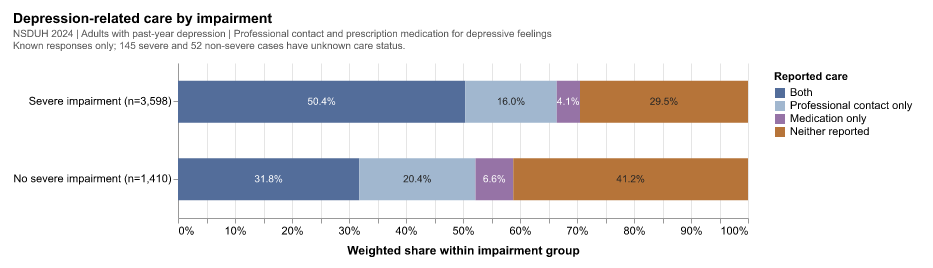

In [13]:
statuses=list(CARE_COLORS)
care_mix=[]
for code_value in [1,0]:
    group=nsduh_care["IRAMDEIMP"].eq(code_value)
    totals=nsduh_care.loc[group].groupby("care_group")["ANALWT2_C"].sum().reindex(statuses,fill_value=0)
    care_mix.append(totals/totals.sum()*100)
care_mix=np.asarray(care_mix)
assert np.allclose(care_mix.sum(axis=1),100)


care_stack_rows = []
for group_code, group_label in [(1, "Severe impairment (n=3,598)"), (0, "No severe impairment (n=1,410)")]:
    group = nsduh_care.loc[nsduh_care["IRAMDEIMP"].eq(group_code)]
    totals = group.groupby("care_group")["ANALWT2_C"].sum().reindex(statuses, fill_value=0)
    cumulative = 0
    for order, status in enumerate(statuses):
        share = float(totals[status] / totals.sum())
        care_stack_rows.append({"impairment": group_label, "care": status, "weight": float(totals[status]),
                                "share": share, "middle": cumulative + share / 2, "order": order})
        cumulative += share
care_stack_df = pd.DataFrame(care_stack_rows)


def care_combinations_chart(df):
    base = alt.Chart(df).encode(
        y=alt.Y("impairment:N", sort=df["impairment"].drop_duplicates().tolist(), title=None),
    )
    bars = base.mark_bar(size=42).encode(
        x=alt.X("sum(weight):Q", title="Weighted share within impairment group").stack("normalize").axis(format="%"),
        color=alt.Color("care:N", title="Reported care", scale=alt.Scale(domain=statuses, range=list(CARE_COLORS.values()))),
        order=alt.Order("order:Q", sort="ascending"),
    )
    labels = base.mark_text(fontSize=10).encode(
        x="middle:Q", text=alt.Text("share:Q", format=".1%"),
        color=alt.condition("datum.care === 'Both' || datum.care === 'Medication only'", alt.value("white"), alt.value("#222222")),
    )
    return (bars + labels).properties(width=570, height=155)


save_chart(
    care_combinations_chart(care_stack_df), "10_depression_care_combinations.png", "Depression-related care by impairment",
    [NSDUH_SOURCE + " | Professional contact and prescription medication for depressive feelings",
     "Known responses only; 145 severe and 52 non-severe cases have unknown care status."],
)


## Figure 11 · Impairment, insurance, and care

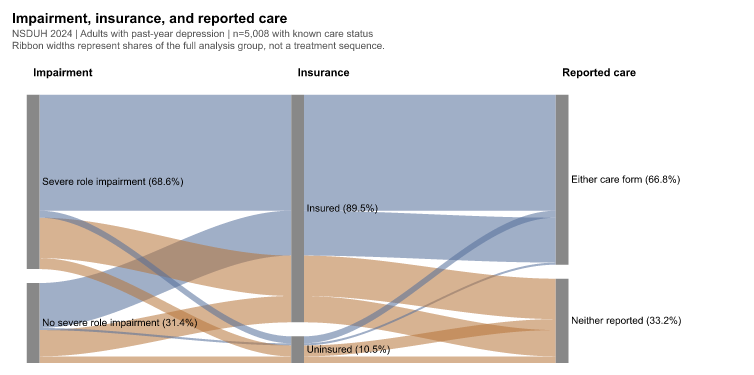

In [14]:
assert nsduh_care["IRAMDEIMP"].isin([0,1]).all() and nsduh_care["IRINSUR4"].isin([1,2]).all()
paths=nsduh_care.groupby(["IRAMDEIMP","IRINSUR4","reported_either"])["ANALWT2_C"].sum()
paths=paths/paths.sum()
assert np.isclose(paths.sum(),1) and len(paths)==8
stage_values=[[1,0],[1,2],[True,False]]
stage_labels=[["Severe role\nimpairment","No severe role\nimpairment"],["Insured","Uninsured"],["Either care form","Neither reported"]]
nodes,slots={},{}
gap=.055
for stage,values in enumerate(stage_values):
    cursor=1+gap
    for value in values:
        members=[p for p in paths.index if p[stage]==value]
        total=sum(paths[p] for p in members)
        top,bottom=cursor,cursor-total
        nodes[stage,value]=(bottom,top,total)
        offset=top
        for p in sorted(members,key=lambda p:(not p[2], -p[0], p[1])):
            slots[stage,p]=(offset-paths[p],offset)
            offset-=paths[p]
        assert np.isclose(offset,bottom)
        cursor=bottom-gap


ribbon_rows, node_rows = [], []
for path, share in paths.items():
    for stage in [0, 1]:
        low0, high0 = slots[stage, path]
        low1, high1 = slots[stage+1, path]
        for fraction in np.linspace(0, 1, 41):
            smooth = fraction*fraction*(3-2*fraction)
            low = low0 + (low1-low0)*smooth
            high = high0 + (high1-high0)*smooth
            assert np.isclose(high-low, share)
            ribbon_rows.append({"ribbon": str(path)+str(stage), "x": stage*.5+.012+fraction*.476,
                                "low": low, "high": high, "care": "Either care form" if path[2] else "Neither reported"})
for stage, values in enumerate(stage_values):
    for value, label in zip(values, stage_labels[stage]):
        bottom, top, share = nodes[stage, value]
        node_rows.append({"x": stage*.5, "left": stage*.5-.012, "right": stage*.5+.012,
                          "low": bottom, "high": top, "middle": (bottom+top)/2,
                          "label": label.replace("\n", " ")+f" ({share:.1%})"})
ribbon_df = pd.DataFrame(ribbon_rows)
node_df = pd.DataFrame(node_rows)
stage_df = pd.DataFrame({"x": [0, .5, 1], "label": ["Impairment", "Insurance", "Reported care"]})


def impairment_insurance_care_chart(ribbons, nodes, stages):
    xs = alt.Scale(domain=[-.04, 1.34], nice=False)
    ys = alt.Scale(domain=[0, 1.18], nice=False)
    flow = alt.Chart(ribbons).mark_area(orient="vertical", opacity=.55).encode(
        x=alt.X("x:Q", scale=xs, axis=None),
        y=alt.Y("low:Q", scale=ys, axis=None, stack=None), y2="high:Q",
        detail="ribbon:N",
        color=alt.Color("care:N", title="Reported care", scale=alt.Scale(domain=["Either care form", "Neither reported"], range=[BLUE, ORANGE]),
                        legend=None),
    )
    bars = alt.Chart(nodes).mark_rect(color="#888888").encode(
        x=alt.X("left:Q", scale=xs, axis=None), x2="right:Q",
        y=alt.Y("low:Q", scale=ys, axis=None), y2="high:Q",
    )
    labels = alt.Chart(nodes).mark_text(align="left", dx=9, fontSize=10).encode(
        x=alt.X("x:Q", scale=xs, axis=None), y=alt.Y("middle:Q", scale=ys, axis=None), text="label:N",
    )
    headings = alt.Chart(stages).mark_text(align="left", fontWeight="bold").encode(
        x=alt.X("x:Q", scale=xs, axis=None), y=alt.datum(1.14), text="label:N",
    )
    return (flow + bars + labels + headings).properties(width=730, height=300)


save_chart(
    impairment_insurance_care_chart(ribbon_df, node_df, stage_df), "11_impairment_insurance_care_alluvial.png",
    "Impairment, insurance, and reported care",
    [NSDUH_SOURCE + " | n=5,008 with known care status",
     "Ribbon widths represent shares of the full analysis group, not a treatment sequence."],
)


## Figure 12 · Insurance and reported care

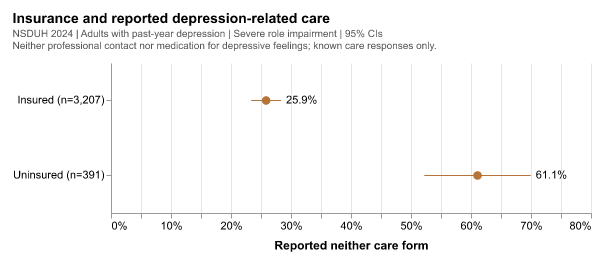

In [15]:
known = nsduh_raw["ATXMDEYR"].isin([0,1]) & nsduh_raw["ARXMDEYR"].isin([0,1])
neither = (nsduh_raw["ATXMDEYR"].eq(0) & nsduh_raw["ARXMDEYR"].eq(0)).astype(float).where(known)
severe = nsduh_raw["IRAMDEYR"].eq(1) & nsduh_raw["IRAMDEIMP"].eq(1)
insurance_rows=[]
for insurance_code,label in [(1,"Insured"),(2,"Uninsured")]:
    result=survey_mean(nsduh_raw,neither,severe & nsduh_raw["IRINSUR4"].eq(insurance_code),**NSDUH_DESIGN)
    insurance_rows.append({"label":label,**result})
insurance_rates=pd.DataFrame(insurance_rows)
assert insurance_rates["n"].tolist()==[3207,391]


insurance_plot = insurance_rates.assign(group=[f"{r.label} (n={r.n:,})" for r in insurance_rates.itertuples()])


def insurance_care_chart(df):
    base = alt.Chart(df).encode(y=alt.Y("group:N", title=None, sort=df["group"].tolist()))
    intervals = base.mark_rule(color=ORANGE).encode(
        x=alt.X("lower:Q", title="Reported neither care form", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .8])), x2="upper:Q",
    )
    points = base.mark_point(filled=True, opacity=1, color=ORANGE, size=75).encode(x="estimate:Q")
    labels = base.mark_text(align="left", dx=5).encode(x="upper:Q", text=alt.Text("estimate:Q", format=".1%"))
    return (intervals + points + labels).properties(width=480, height=150)


save_chart(
    insurance_care_chart(insurance_plot), "12_insurance_care_comparison.png", "Insurance and reported depression-related care",
    [NSDUH_SOURCE + " | Severe role impairment | 95% CIs",
     "Neither professional contact nor medication for depressive feelings; known care responses only."],
)


## Figure 13 · Care out of 100

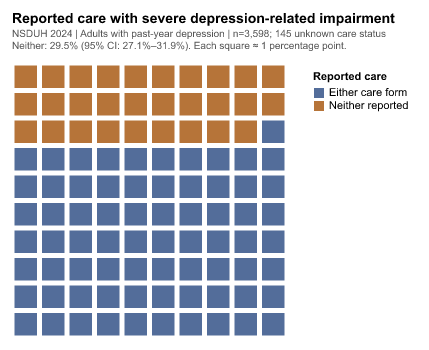

In [16]:
closing=survey_mean(nsduh_raw,neither,severe,**NSDUH_DESIGN)
no_care_pct=closing["estimate"]*100
rounded=int(np.floor(no_care_pct+.5))
unknown_severe=int((severe & ~known).sum())
assert closing["n"]==3598 and unknown_severe==145


waffle_df = pd.DataFrame([
    {"row": i//10, "column": i%10, "care": "Neither reported" if i<rounded else "Either care form"}
    for i in range(100)
])


def care_waffle_chart(df):
    return alt.Chart(df).mark_square(size=510, opacity=1).encode(
        x=alt.X("column:O", axis=None), y=alt.Y("row:O", axis=None),
        color=alt.Color("care:N", title="Reported care", scale=alt.Scale(domain=["Either care form", "Neither reported"], range=[BLUE, ORANGE])),
    ).properties(width=275, height=275)


save_chart(
    care_waffle_chart(waffle_df), "13_care_out_of_100_waffle.png", "Reported care with severe depression-related impairment",
    [NSDUH_SOURCE + " | n=3,598; 145 unknown care status",
     f"Neither: {no_care_pct:.1f}% (95% CI: {closing['lower']:.1%}–{closing['upper']:.1%}). Each square ≈ 1 percentage point."],
)
